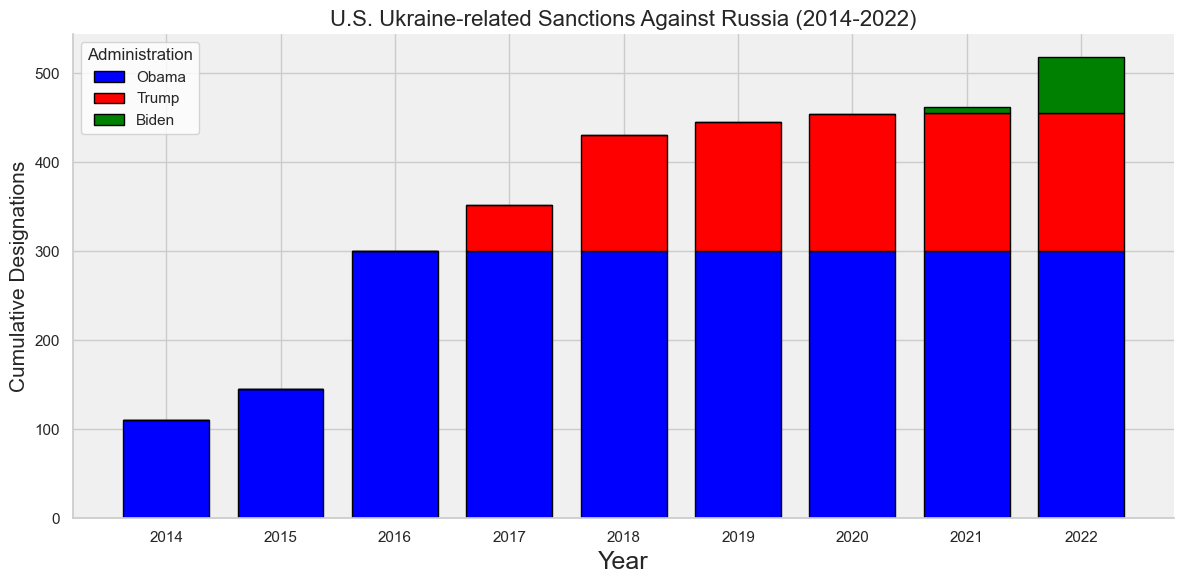

In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("sanctions_table.csv")

df["Administration"] = df["Administration"].str.strip()
df["Year"] = pd.to_numeric(df["Year"], errors = "coerce")

df = df[df["Year"].between(2014, 2022)]

counts = (
    df.groupby(["Year", "Administration"])
    .size()
    .unstack(fill_value = 0))

counts = counts.reindex(range(2014, 2023), fill_value = 0)

counts = counts.reindex(
    columns=["Obama", "Trump", "Biden"],
    fill_value = 0)

cumulative = counts.cumsum()

colors = {
    "Obama": "blue",
    "Trump": "red",
    "Biden": "green"}

sns.set_theme(style = "whitegrid")

fig, ax = plt.subplots(figsize = (12, 6))

bottom = pd.Series(0, index = cumulative.index)

for admin in ["Obama", "Trump", "Biden"]:
    ax.bar(
        cumulative.index,
        cumulative[admin],
        bottom = bottom,
        color = colors[admin],
        edgecolor = "black",
        linewidth = 1,
        label = admin,
        width = 0.75)

    bottom += cumulative[admin]


ax.set_title(
    "U.S. Ukraine-related Sanctions Against Russia (2014-2022)",
    fontsize = 16)
ax.set_xlabel("Year", fontsize = 18)
ax.set_ylabel("Cumulative Designations", fontsize = 15)

ax.set_xticks(range(2014, 2023))
ax.set_ylim(bottom = 0)

ax.legend(title = "Administration")

ax.set_facecolor("#F0F0F0")

sns.despine()
plt.tight_layout()
plt.show()